In [2]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

import warnings
warnings.filterwarnings('ignore')

# Load training and testing datasets
df=pd.read_csv('/content/drive/MyDrive/diabetes (1).csv')


# Display the first few rows
print(df.head())

   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  


In [4]:
df.shape
df.info()
df.describe().T
df.columns

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


Index(['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome'],
      dtype='object')

In [5]:
#target variable
df.Outcome.value_counts()

,count
Outcome,
0,500
1,268


In [6]:
df[['Glucose','BloodPressure','SkinThickness','Insulin','BMI']] = df[['Glucose','BloodPressure','SkinThickness','Insulin','BMI']].replace(0,np.nan)
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148.0,72.0,35.0,NaN,33.6,0.627,50,1
1,1,85.0,66.0,29.0,NaN,26.6,0.351,31,0
2,8,183.0,64.0,NaN,NaN,23.3,0.672,32,1
3,1,89.0,66.0,23.0,94.0,28.1,0.167,21,0
4,0,137.0,40.0,35.0,168.0,43.1,2.288,33,1


In [7]:
print(df.isnull().sum())  # Check missing values in training data


Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64


In [8]:
df.isnull().sum()

,0
Pregnancies,0
Glucose,5
BloodPressure,35
SkinThickness,227
Insulin,374
BMI,11
DiabetesPedigreeFunction,0
Age,0
Outcome,0


<Axes: >

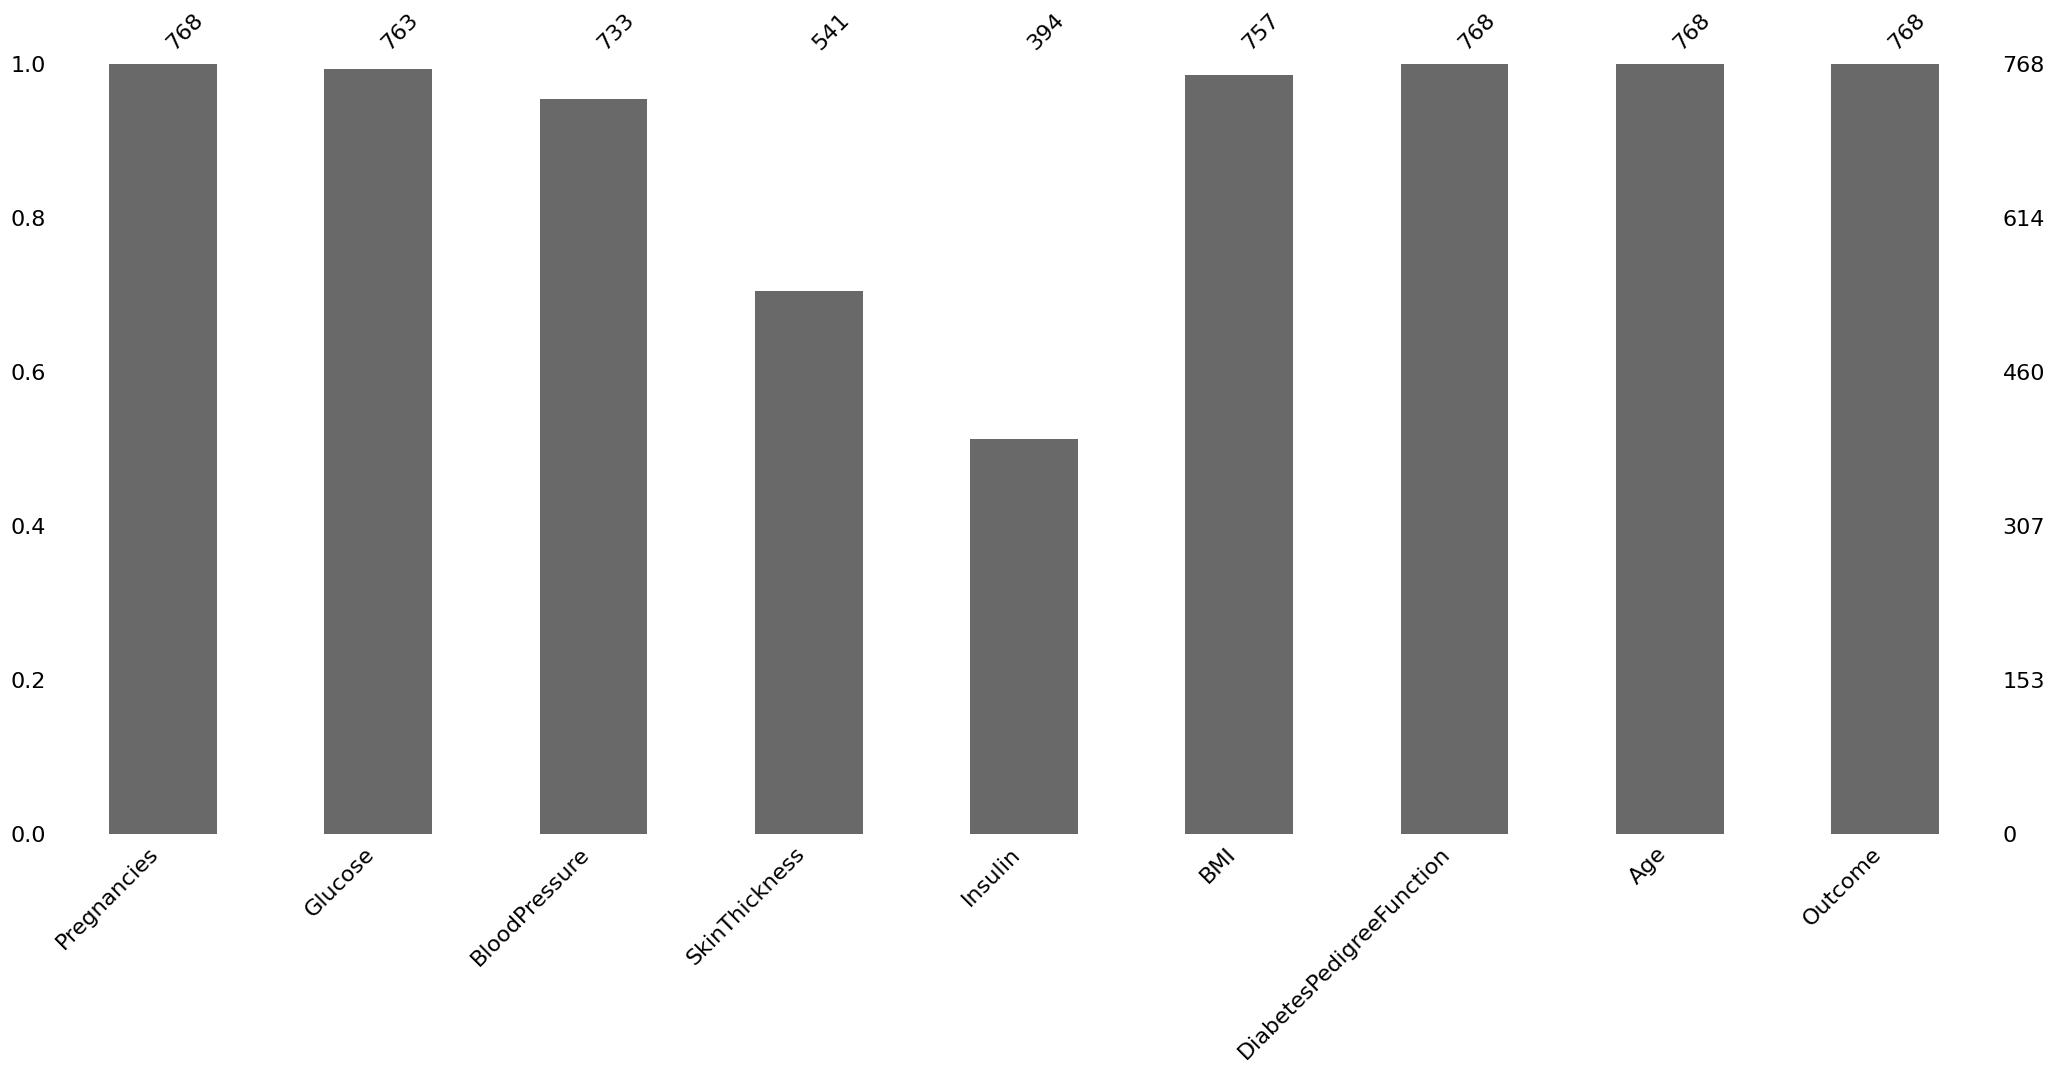

In [9]:
#visualizing null values
import missingno as msno
msno.bar(df)

In [10]:
def median_target(var):
    temp = df[df[var].notnull()]
    temp = temp[[var, 'Outcome']].groupby(['Outcome'])[[var]].median().reset_index()
    return temp

In [11]:
columns = df.columns
columns = columns.drop("Outcome")
for i in columns:
    median_target(i)
    df.loc[(df['Outcome'] == 0 ) & (df[i].isnull()), i] = median_target(i)[i][0]
    df.loc[(df['Outcome'] == 1 ) & (df[i].isnull()), i] = median_target(i)[i][1]

In [12]:
df.head()
df.isnull().sum()


,0
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
Outcome,0


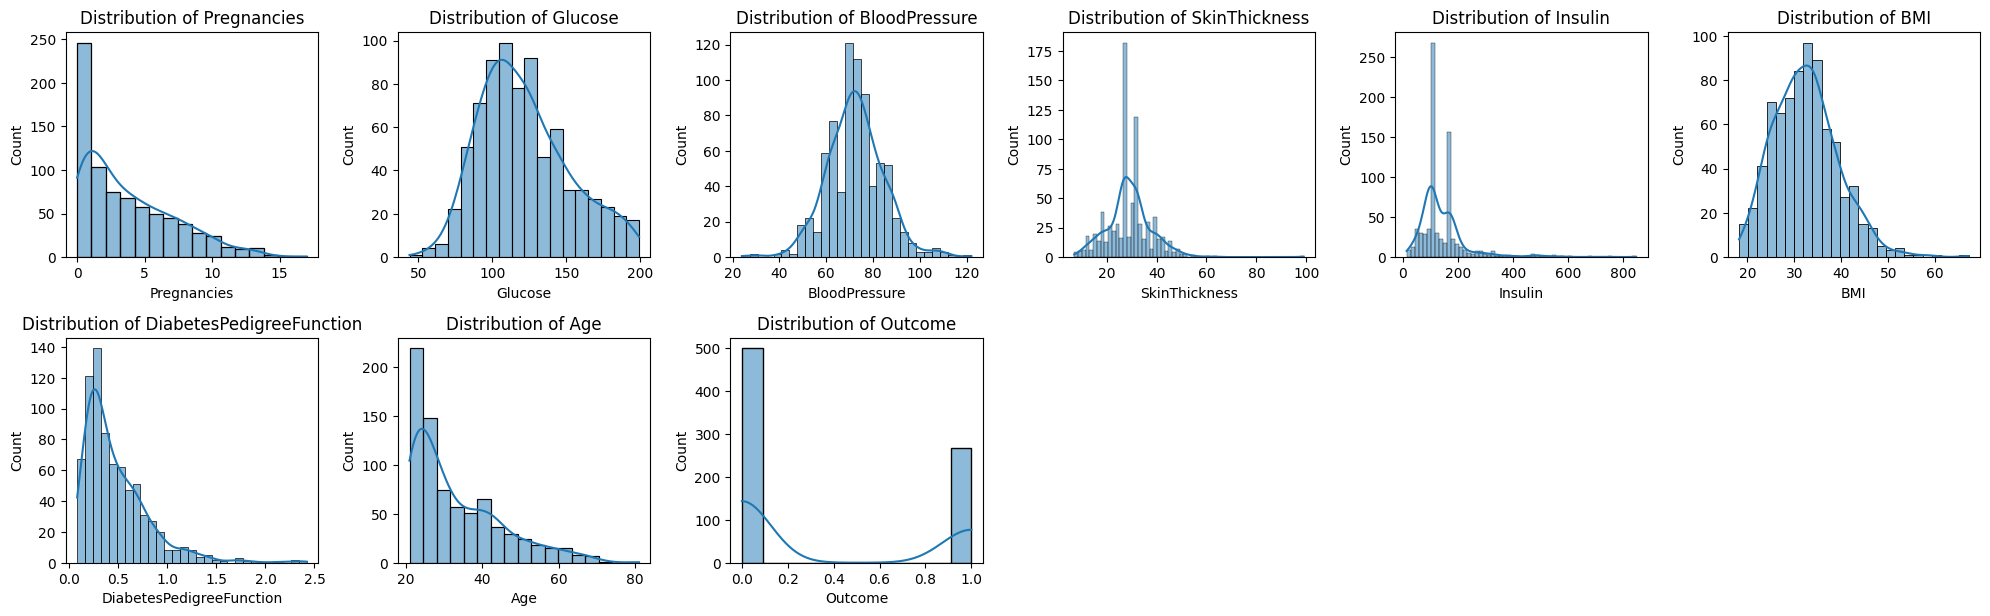

In [13]:
#histplot
import seaborn as sns
import matplotlib.pyplot as plt
plt.figure(figsize=(20, 15))
plotnumber = 1

for column in df.columns:
    if plotnumber <= 30:
        ax = plt.subplot(5, 6, plotnumber)  # Creates a grid of 5 rows and 6 columns
        sns.histplot(df[column], kde=True)  # Use histplot with kde for density
        plt.xlabel(column)
        plt.title(f'Distribution of {column}')

    plotnumber += 1

plt.tight_layout()
plt.show()

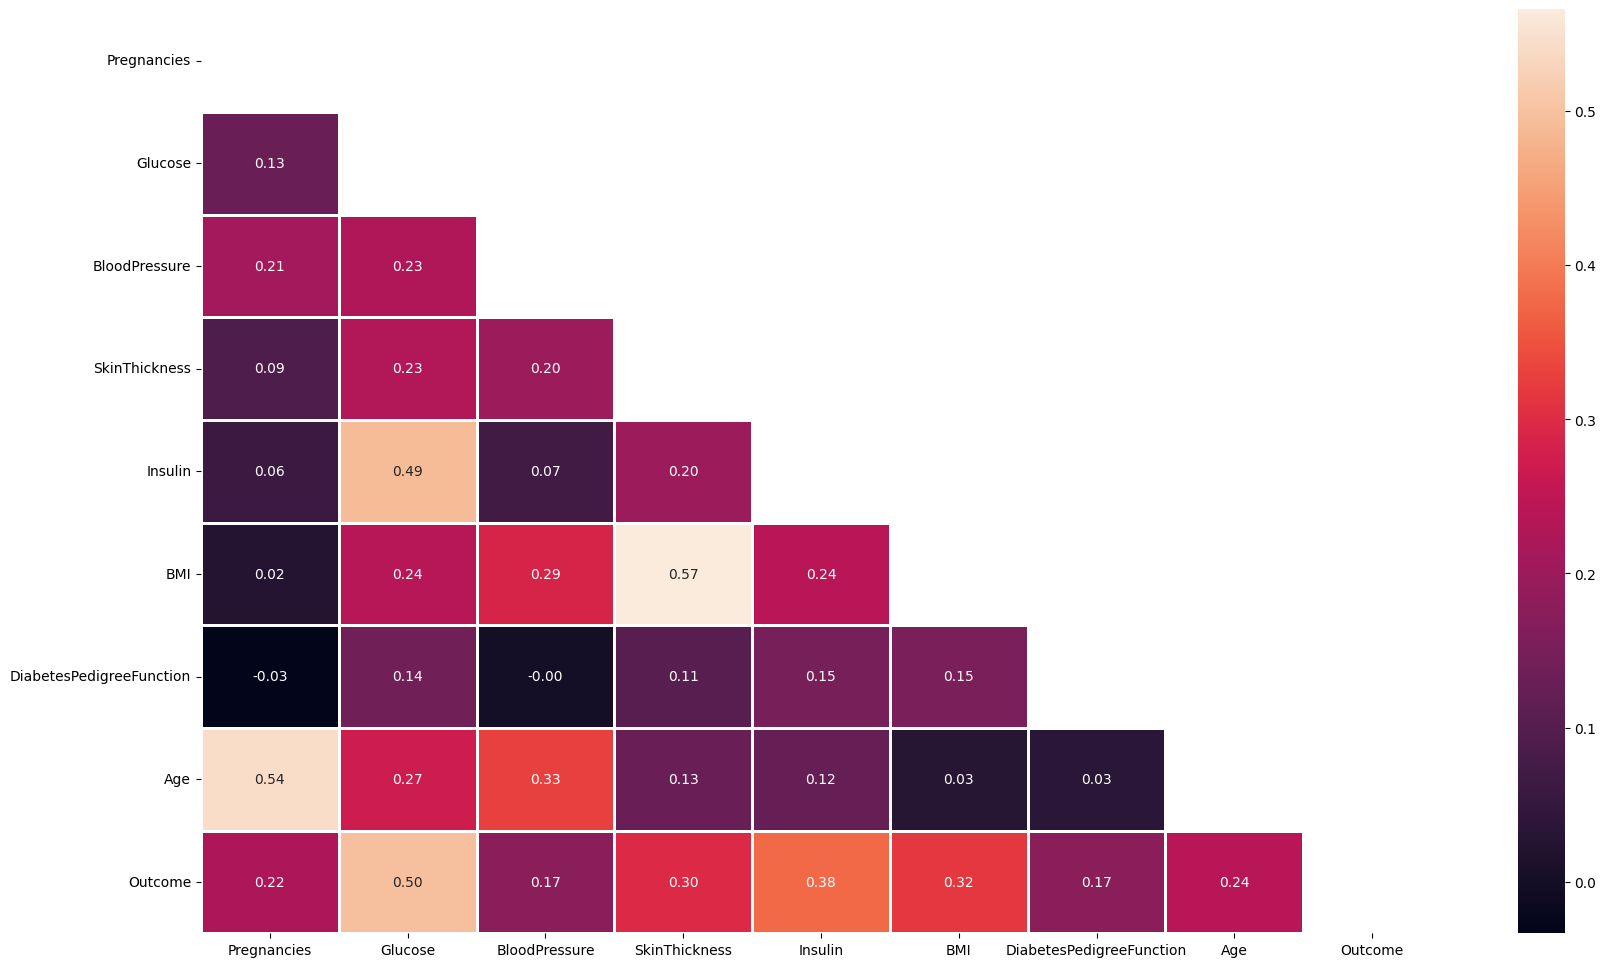

In [14]:
#heatmap
import numpy as np
plt.figure(figsize = (20, 12))

corr = df.corr()
mask = np.triu(np.ones_like(corr, dtype = bool))

sns.heatmap(corr, mask = mask, linewidths = 1, annot = True, fmt = ".2f")
plt.show()

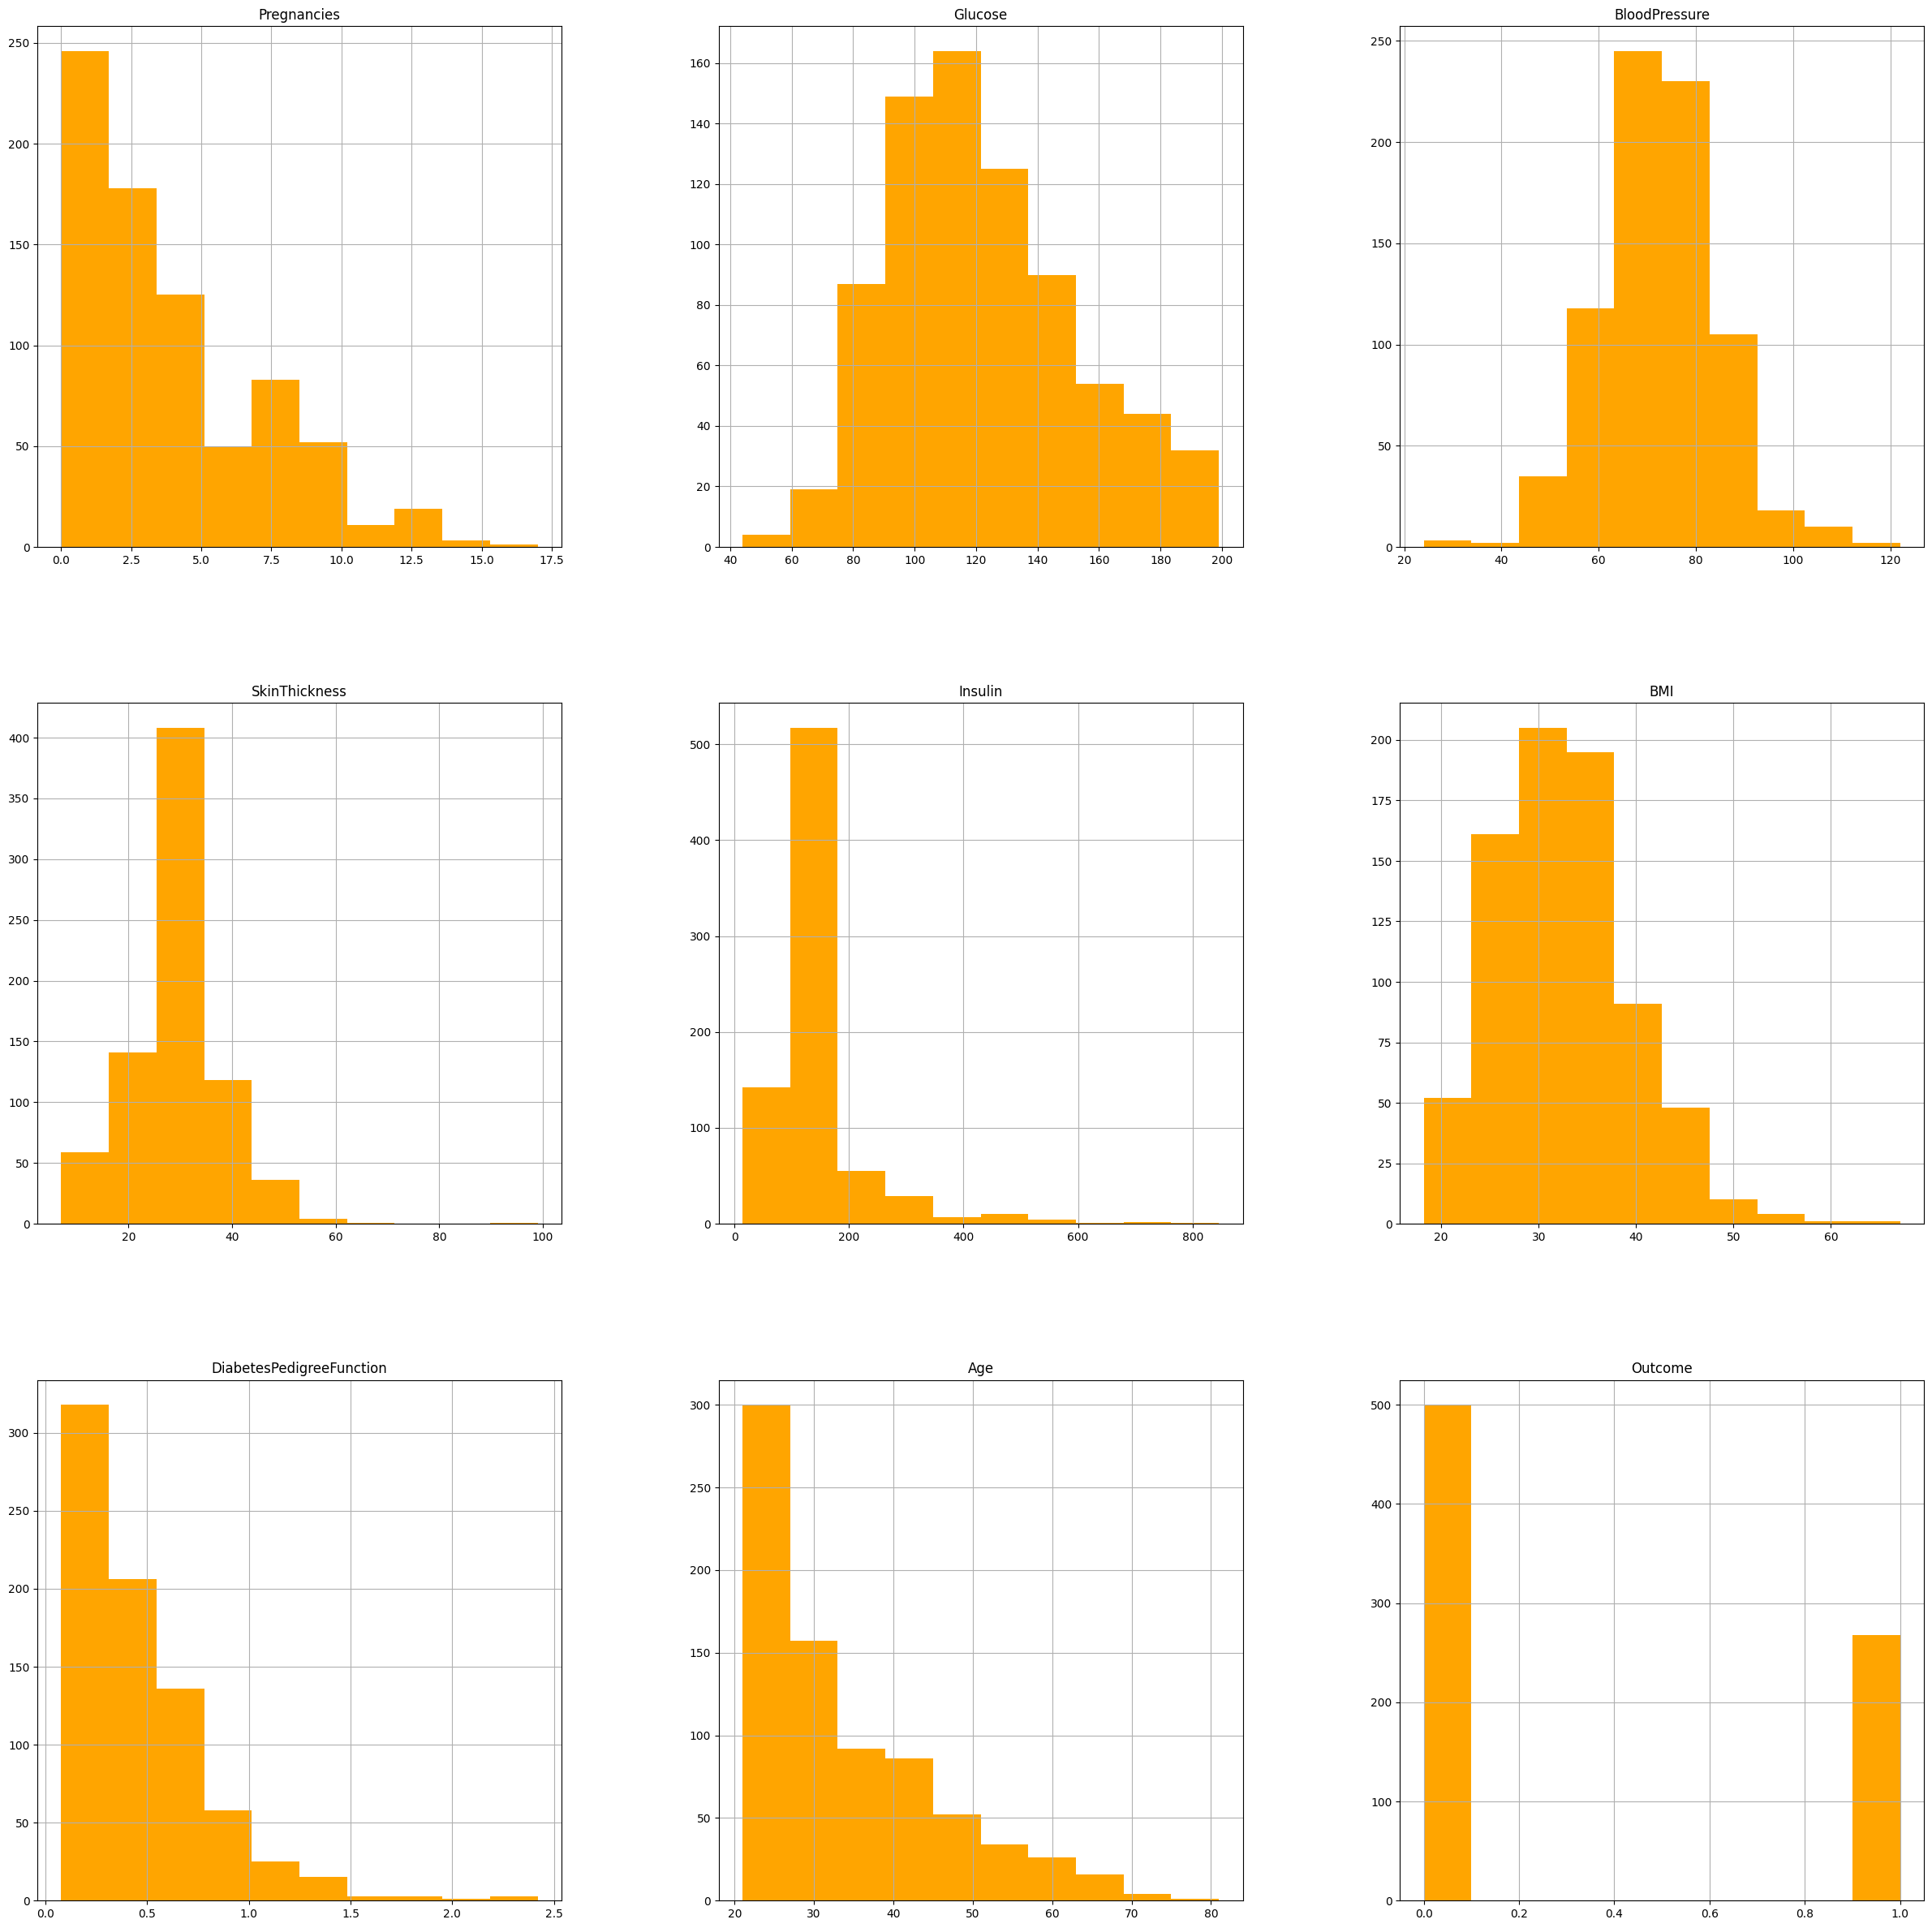

In [15]:
#plot the histograms for each feature:
df.hist(figsize = (30,30), color = 'orange')
plt.show()

In [16]:
# removing highly correlated features

corr_matrix = df.corr().abs()

mask = np.triu(np.ones_like(corr_matrix, dtype = bool))
tri_df = corr_matrix.mask(mask)

to_drop = [x for x in tri_df.columns if any(tri_df[x] > 0.92)]

df = df.drop(to_drop, axis = 1)

print(f"The reduced dataframe has {df.shape[1]} columns.")

The reduced dataframe has 9 columns.


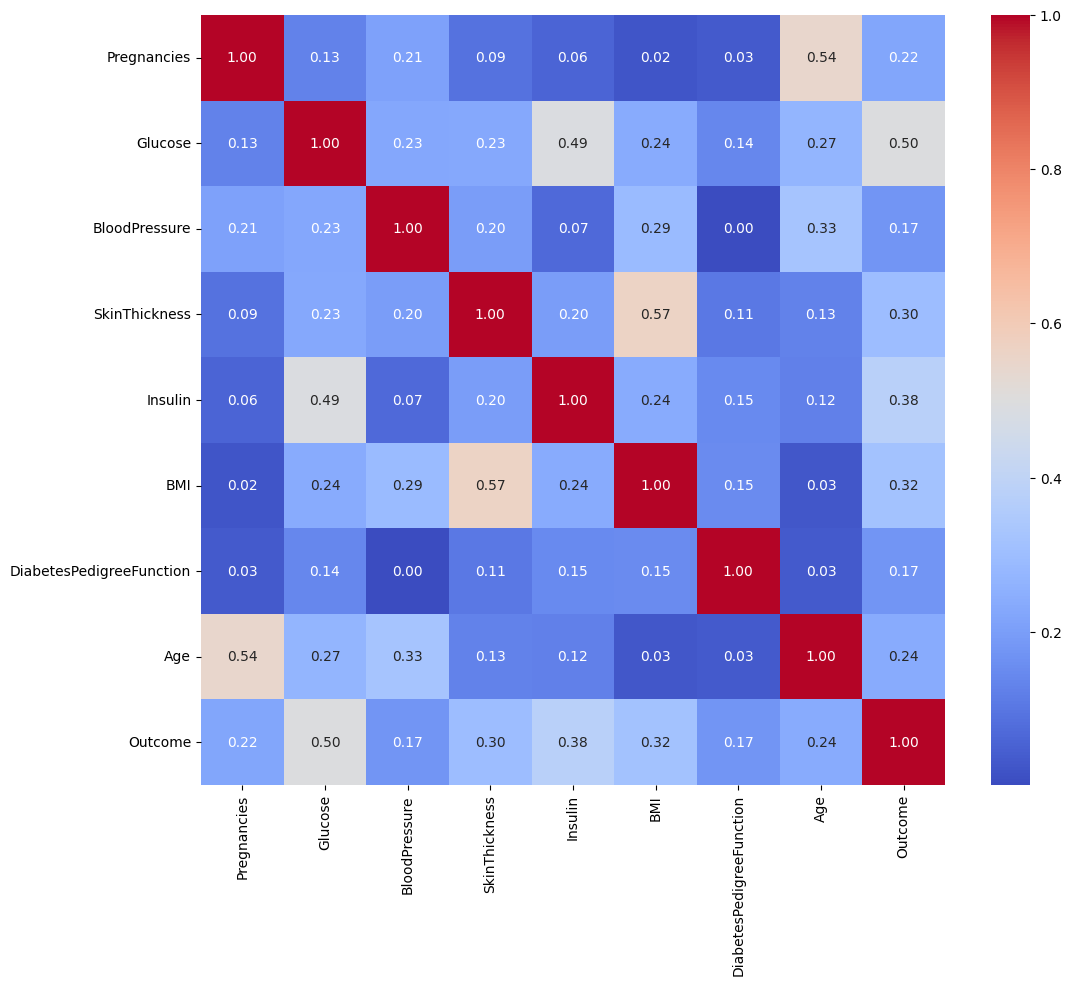

In [17]:
# Recalculate the correlation matrix
new_corr_matrix = df.corr().abs()
plt.figure(figsize=(12, 10))
sns.heatmap(new_corr_matrix, annot=True, fmt='.2f', cmap='coolwarm')
plt.show()

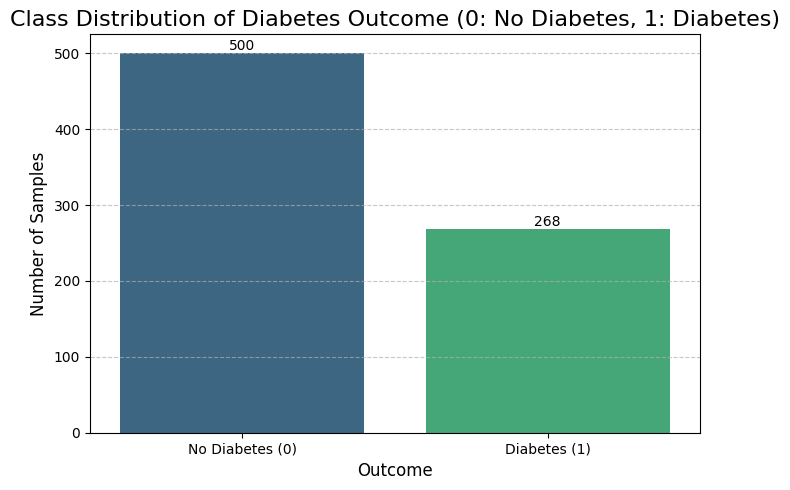


Actual Class Counts:
Outcome
0    500
1    268
Name: count, dtype: int64

Class Distribution Percentage:
Outcome
0    65.104167
1    34.895833
Name: proportion, dtype: float64


In [18]:
plt.figure(figsize=(7, 5))
sns.countplot(x='Outcome', data=df, palette='viridis')

# Add titles and labels
plt.title('Class Distribution of Diabetes Outcome (0: No Diabetes, 1: Diabetes)', fontsize=16)
plt.xlabel('Outcome', fontsize=12)
plt.ylabel('Number of Samples', fontsize=12)
plt.xticks(ticks=[0, 1], labels=['No Diabetes (0)', 'Diabetes (1)'])

# Add counts on top of the bars
for p in plt.gca().patches:
    plt.gca().annotate(f'{int(p.get_height())}',
                       (p.get_x() + p.get_width() / 2., p.get_height()),
                       ha='center', va='center',
                       xytext=(0, 5),
                       textcoords='offset points',
                       fontsize=10,
                       color='black')

plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

# --- 3. Print the actual counts ---
print("\nActual Class Counts:")
print(df['Outcome'].value_counts())
print("\nClass Distribution Percentage:")
print(df['Outcome'].value_counts(normalize=True) * 100)


In [19]:
# creating features and label

X = df.drop('Outcome', axis = 1)
y = df['Outcome']

In [20]:
# Splitting the data into training set and testset
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size = 0.2, random_state = 0)
print("Size of training set:", X_train.shape)
print("Size of test set:", X_test.shape)

Size of training set: (614, 8)
Size of test set: (154, 8)


In [21]:
X_train, X_test = X_train.align(X_test, join="left", axis=1, fill_value=0)

Imbalanced Dataset Oversampling using SMOTE

In [22]:
import imblearn
from imblearn.over_sampling import SMOTE
from collections import Counter

counter = Counter(y_train)
counter

Counter({1: 221, 0: 393})

In [23]:
upsample = SMOTE()
X_train, y_train = upsample.fit_resample(X_train, y_train)
counter = Counter(y_train)
print(counter)

Counter({1: 393, 0: 393})


In [24]:
print(f"Train Data: {X_train.shape}, {y_train.shape}")
print(f"Test Data: {X_test.shape}, {y_test.shape}")

Train Data: (786, 8), (786,)
Test Data: (154, 8), (154,)


In [25]:
# scaling data

from sklearn.preprocessing import RobustScaler

scaler = RobustScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

#Visualization and Feature Extraction

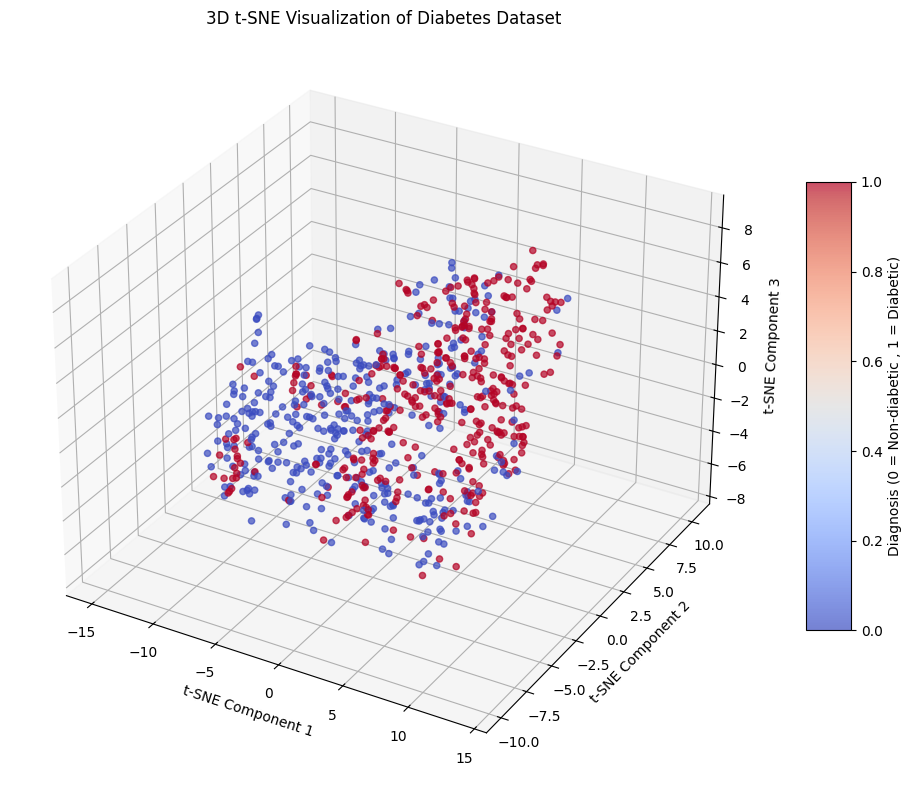

In [26]:
from mpl_toolkits.mplot3d import Axes3D  # for 3D plotting
from sklearn.manifold import TSNE

# Apply t-SNE with 3 components
tsne = TSNE(n_components=3, perplexity=60, n_iter=1000, random_state=42)
X_tsne = tsne.fit_transform(X_train)

# #D Visualization
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

# Scatter plot
scatter = ax.scatter(X_tsne[:, 0], X_tsne[:, 1], X_tsne[:, 2],
                     c=y_train, cmap='coolwarm', alpha=0.7)

# Labels and title
ax.set_title("3D t-SNE Visualization of Diabetes Dataset")
ax.set_xlabel("t-SNE Component 1")
ax.set_ylabel("t-SNE Component 2")
ax.set_zlabel("t-SNE Component 3")

# Color legend
legend = fig.colorbar(scatter, ax=ax, shrink=0.6, aspect=10)
legend.set_label("Diagnosis (0 = Non-diabetic , 1 = Diabetic)")

plt.tight_layout()
plt.show()

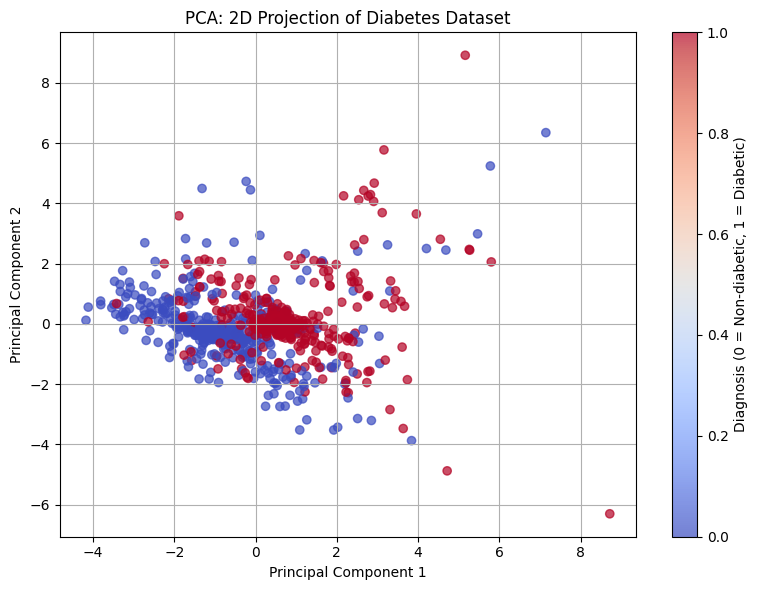

In [27]:
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_train)

# Plot
plt.figure(figsize=(8, 6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y_train, cmap='coolwarm', alpha=0.7)
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('PCA: 2D Projection of Diabetes Dataset')
plt.colorbar(label='Diagnosis (0 = Non-diabetic, 1 = Diabetic)')
plt.grid(True)
plt.tight_layout()
plt.show()

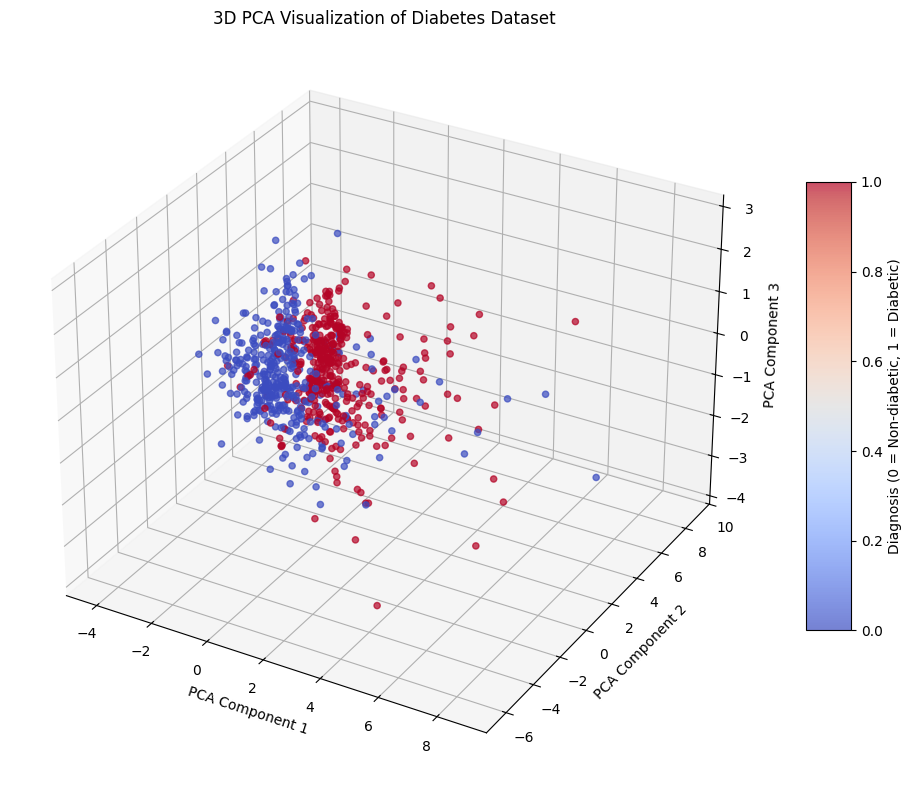

In [28]:
pca = PCA(n_components=3)
X_pca_3d = pca.fit_transform(X_train)

# Plotting 3D PCA
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

scatter = ax.scatter(
    X_pca_3d[:, 0], X_pca_3d[:, 1], X_pca_3d[:, 2],
    c=y_train, cmap='coolwarm', alpha=0.7
)

ax.set_title("3D PCA Visualization of Diabetes Dataset")
ax.set_xlabel("PCA Component 1")
ax.set_ylabel("PCA Component 2")
ax.set_zlabel("PCA Component 3")

cbar = fig.colorbar(scatter, ax=ax, shrink=0.6, aspect=10)
cbar.set_label("Diagnosis (0 = Non-diabetic, 1 = Diabetic)")

plt.tight_layout()
plt.show()

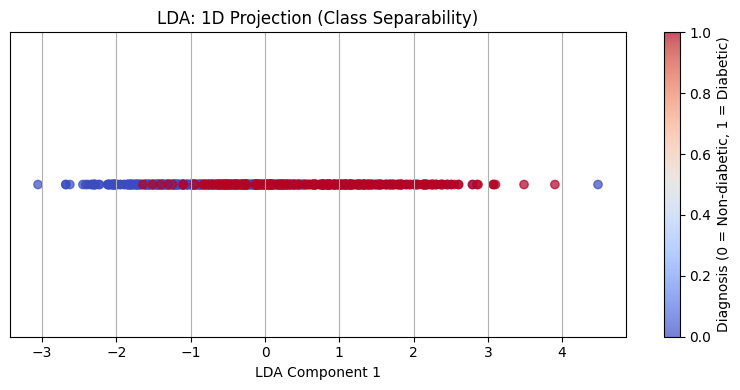

In [29]:
# Apply LDA
lda = LDA(n_components=1)
X_lda = lda.fit_transform(X_train, y_train)

# Plot
plt.figure(figsize=(8, 4))
plt.scatter(X_lda[:, 0], [0]*len(X_lda), c=y_train, cmap='coolwarm', alpha=0.7)
plt.xlabel('LDA Component 1')
plt.title('LDA: 1D Projection (Class Separability)')
plt.yticks([])
plt.colorbar(label='Diagnosis (0 = Non-diabetic, 1 = Diabetic)')
plt.grid(True)
plt.tight_layout()
plt.show()

##Feature Extraction using PCA and LDA on decision tree

In [30]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
# Step 1: Apply LDA (only 1 component since it's binary classification)
lda = LDA(n_components=1)
X_train_lda = lda.fit_transform(X_train, y_train)
X_test_lda = lda.transform(X_test)

# Step 2: Classification using decision tree
clf_lda_dt = DecisionTreeClassifier(random_state=42)

# Train the model on the LDA-transformed training data
clf_lda_dt.fit(X_train_lda, y_train)

print("\nDecision Tree Classifier trained on LDA-transformed data.")

# Step 3 : Evaluation
y_pred_lda_dt = clf_lda_dt.predict(X_test_lda)

print("\n--- Model Evaluation ---")
print(f" LDA + Decision tree Accuracy: {accuracy_score(y_test, y_pred_lda_dt):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_lda_dt))

# confusion matrix

print(confusion_matrix(y_test, y_pred_lda_dt))


Decision Tree Classifier trained on LDA-transformed data.

--- Model Evaluation ---
 LDA + Decision tree Accuracy: 0.7208

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.73      0.78       107
           1       0.53      0.70      0.61        47

    accuracy                           0.72       154
   macro avg       0.69      0.72      0.69       154
weighted avg       0.75      0.72      0.73       154

[[78 29]
 [14 33]]


In [31]:

# from  sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Apply PCA
pca = PCA(n_components=6)
X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)

# Classification using decision tree
clf_pca_dt = DecisionTreeClassifier(random_state=42)

clf_pca_dt.fit(X_train_pca, y_train)

# Evaluation
y_pred_pca_dt = clf_pca_dt.predict(X_test_pca)
print("PCA + DT Accuracy:", accuracy_score(y_test, y_pred_pca_dt))
print(classification_report(y_test, y_pred_pca_dt))

# confusion matrix

print(confusion_matrix(y_test, y_pred_pca_dt))

PCA + DT Accuracy: 0.7532467532467533
              precision    recall  f1-score   support

           0       0.90      0.73      0.80       107
           1       0.57      0.81      0.67        47

    accuracy                           0.75       154
   macro avg       0.73      0.77      0.74       154
weighted avg       0.80      0.75      0.76       154

[[78 29]
 [ 9 38]]


##XGBOOST with pca and lda + randomsearchcv


Starting RandomizedSearchCV for LDA + XGBoost...
Fitting 5 folds for each of 50 candidates, totalling 250 fits

--- LDA + XGBoost Evaluation ---
Best Hyperparameters (LDA): {'subsample': 0.7, 'reg_lambda': 0, 'reg_alpha': 0.01, 'n_estimators': 300, 'max_depth': 3, 'learning_rate': 0.01, 'gamma': 0.2, 'colsample_bytree': 0.6}
Best Cross-Validation Accuracy (LDA): 0.7684

Test Accuracy (LDA + XGBoost): 0.7987

Classification Report (LDA + XGBoost):
              precision    recall  f1-score   support

           0       0.90      0.79      0.85       107
           1       0.63      0.81      0.71        47

    accuracy                           0.80       154
   macro avg       0.77      0.80      0.78       154
weighted avg       0.82      0.80      0.80       154


Confusion Matrix (LDA + XGBoost):
[[85 22]
 [ 9 38]]


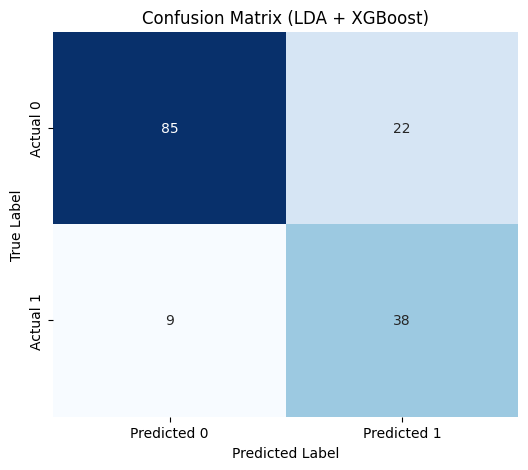

In [32]:

from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix





# Apply Linear Discriminant Analysis (LDA) for Feature Extraction


# Define XGBoost Classifier and Hyperparameter Distribution for RandomizedSearchCV
xgb_model = XGBClassifier(random_state=42)


param_distributions = {
    'n_estimators': [100, 200, 300, 400, 500],
    'learning_rate': [0.01, 0.05, 0.1, 0.2, 0.3],
    'max_depth': [3, 4, 5, 6, 7],
    'subsample': [0.6, 0.7, 0.8, 0.9, 1.0],
    'colsample_bytree': [0.6, 0.7, 0.8, 0.9, 1.0],
    'gamma': [0, 0.1, 0.2, 0.3, 0.4],
    'reg_alpha': [0, 0.005, 0.01, 0.05, 0.1], # L1 regularization
    'reg_lambda': [0, 0.005, 0.01, 0.05, 0.1] # L2 regularization
}




random_search_lda = RandomizedSearchCV(
    estimator=xgb_model,
    param_distributions=param_distributions,
    n_iter=50,
    scoring='accuracy',
    cv=5,
    verbose=1,
    random_state=42,
    n_jobs=-1 # Use all available CPU cores
)

print("\nStarting RandomizedSearchCV for LDA + XGBoost...")
random_search_lda.fit(X_train_lda, y_train)

# Evaluate the Best Model
print("\n--- LDA + XGBoost Evaluation ---")
print(f"Best Hyperparameters (LDA): {random_search_lda.best_params_}")
print(f"Best Cross-Validation Accuracy (LDA): {random_search_lda.best_score_:.4f}")

best_xgb_lda = random_search_lda.best_estimator_
y_pred_lda_xgb = best_xgb_lda.predict(X_test_lda)

print(f"\nTest Accuracy (LDA + XGBoost): {accuracy_score(y_test, y_pred_lda_xgb):.4f}")
print("\nClassification Report (LDA + XGBoost):")
print(classification_report(y_test, y_pred_lda_xgb))

cm_lda_xgb = confusion_matrix(y_test, y_pred_lda_xgb)
print("\nConfusion Matrix (LDA + XGBoost):")
print(cm_lda_xgb)

plt.figure(figsize=(6, 5))
sns.heatmap(cm_lda_xgb, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Predicted 0', 'Predicted 1'],
            yticklabels=['Actual 0', 'Actual 1'])
plt.title('Confusion Matrix (LDA + XGBoost)')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()


XGBoost Classifier instantiated with fixed hyperparameters.

XGBoost Classifier trained on PCA-transformed data.

--- PCA + XGBoost Evaluation (Fixed Hyperparameters) ---
Test Accuracy: 0.8377

Classification Report:
              precision    recall  f1-score   support

           0       0.92      0.84      0.88       107
           1       0.70      0.83      0.76        47

    accuracy                           0.84       154
   macro avg       0.81      0.84      0.82       154
weighted avg       0.85      0.84      0.84       154


Confusion Matrix:
[[90 17]
 [ 8 39]]


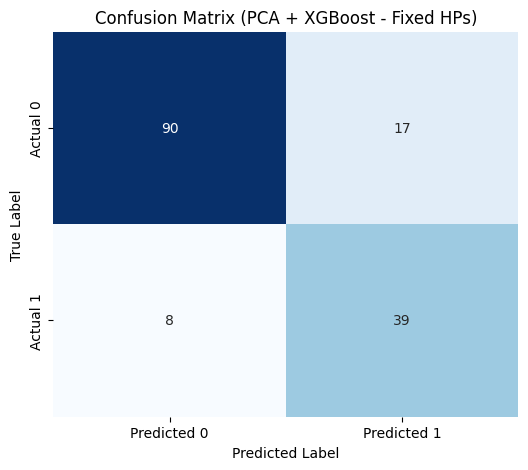

In [33]:

from sklearn.decomposition import PCA # Import PCA
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix







xgb_model_pca = XGBClassifier(
    random_state=42,

    #  hyperparameters
    subsample=0.8,
    reg_lambda=0,
    reg_alpha=0,
    n_estimators=300,
    max_depth=3,
    learning_rate=0.1,
    gamma=0,
    colsample_bytree=1.0
)

print("\nXGBoost Classifier instantiated with fixed hyperparameters.")

#  Train the XGBoost Model
xgb_model_pca.fit(X_train_pca, y_train)

print("\nXGBoost Classifier trained on PCA-transformed data.")

#  Make Predictions and Evaluate the Model
y_pred_pca_xgb = xgb_model_pca.predict(X_test_pca)

print("\n--- PCA + XGBoost Evaluation (Fixed Hyperparameters) ---")
print(f"Test Accuracy: {accuracy_score(y_test, y_pred_pca_xgb):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_pca_xgb))

cm_pca_xgb = confusion_matrix(y_test, y_pred_pca_xgb)
print("\nConfusion Matrix:")
print(cm_pca_xgb)

plt.figure(figsize=(6, 5))
sns.heatmap(cm_pca_xgb, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Predicted 0', 'Predicted 1'],
            yticklabels=['Actual 0', 'Actual 1'])
plt.title('Confusion Matrix (PCA + XGBoost - Fixed HPs)')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()




Starting RandomizedSearchCV for PCA + XGBoost (tuning all HPs)...
Fitting 5 folds for each of 100 candidates, totalling 500 fits

--- PCA + XGBoost Evaluation ---
Best Hyperparameters found: {'subsample': 0.7, 'reg_lambda': 0, 'reg_alpha': 0, 'n_estimators': 400, 'max_depth': 10, 'learning_rate': 0.05, 'gamma': 0, 'colsample_bytree': 0.7}
Best Cross-Validation Accuracy: 0.8677

Test Accuracy (PCA + XGBoost - Tuned HPs): 0.8571

Classification Report (PCA + XGBoost - Tuned HPs):
              precision    recall  f1-score   support

           0       0.92      0.87      0.89       107
           1       0.74      0.83      0.78        47

    accuracy                           0.86       154
   macro avg       0.83      0.85      0.84       154
weighted avg       0.86      0.86      0.86       154


Confusion Matrix (PCA + XGBoost - Tuned HPs):
[[93 14]
 [ 8 39]]


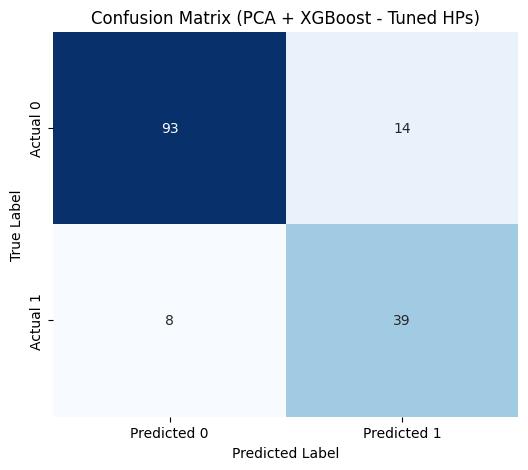

In [34]:

xgb_model_pca_r = XGBClassifier(random_state=42)


param_distributions = {
    'n_estimators': [100, 200, 300, 400, 500, 600, 700],
    'learning_rate': [0.01, 0.05, 0.1, 0.15, 0.2, 0.25, 0.3],
    'max_depth': [3, 4, 5, 6, 7, 8, 9, 10],
    'subsample': [0.6, 0.7, 0.8, 0.9, 1.0],
    'colsample_bytree': [0.6, 0.7, 0.8, 0.9, 1.0],
    'gamma': [0, 0.1, 0.2, 0.3, 0.4, 0.5],
    'reg_alpha': [0, 0.001, 0.005, 0.01, 0.05, 0.1, 0.5, 1], # L1 regularization
    'reg_lambda': [0, 0.001, 0.005, 0.01, 0.05, 0.1, 0.5, 1] # L2 regularization
}

# Define RandomizedSearchCV
random_search_pca_r = RandomizedSearchCV(
    estimator=xgb_model_pca_r,
    param_distributions=param_distributions,
    n_iter=100,
    scoring='accuracy',
    cv=5,
    verbose=2,
    random_state=42,
    n_jobs=-1 # Use all available CPU cores
)

print("\nStarting RandomizedSearchCV for PCA + XGBoost (tuning all HPs)...")
random_search_pca_r.fit(X_train_pca, y_train)

#  Evaluate the Best Model ---
print("\n--- PCA + XGBoost Evaluation ---")
print(f"Best Hyperparameters found: {random_search_pca_r.best_params_}")
print(f"Best Cross-Validation Accuracy: {random_search_pca_r.best_score_:.4f}")

best_xgb_pca_r = random_search_pca_r.best_estimator_
y_pred_pca_xgb_r = best_xgb_pca_r.predict(X_test_pca)

print(f"\nTest Accuracy (PCA + XGBoost - Tuned HPs): {accuracy_score(y_test, y_pred_pca_xgb_r):.4f}")
print("\nClassification Report (PCA + XGBoost - Tuned HPs):")
print(classification_report(y_test, y_pred_pca_xgb_r))

cm_pca_xgb_r = confusion_matrix(y_test, y_pred_pca_xgb_r)
print("\nConfusion Matrix (PCA + XGBoost - Tuned HPs):")
print(cm_pca_xgb_r)

plt.figure(figsize=(6, 5))
sns.heatmap(cm_pca_xgb_r, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Predicted 0', 'Predicted 1'],
            yticklabels=['Actual 0', 'Actual 1'])
plt.title('Confusion Matrix (PCA + XGBoost - Tuned HPs)')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()


##pca random forest


Random Forest Classifier trained on PCA-transformed data.

--- PCA + Random Forest Evaluation (Fixed Hyperparameters) ---
Test Accuracy: 0.8701

Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.87      0.90       107
           1       0.75      0.87      0.80        47

    accuracy                           0.87       154
   macro avg       0.84      0.87      0.85       154
weighted avg       0.88      0.87      0.87       154


Confusion Matrix:
[[93 14]
 [ 6 41]]


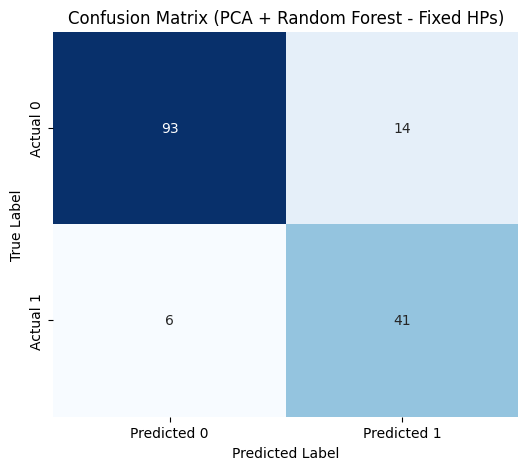

In [35]:

from sklearn.ensemble import RandomForestClassifier # Import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
clf_pca_rf = RandomForestClassifier(
    n_estimators=500,
    max_depth=8,
    min_samples_split=2,
    max_features=7,
    random_state=42,
    n_jobs=-1 # Use all available CPU cores
)

#  Train the Random Forest Model ---
clf_pca_rf.fit(X_train_pca, y_train)

print("\nRandom Forest Classifier trained on PCA-transformed data.")


#   Make Predictions and Evaluate the Model ---
y_pred_pca_rf = clf_pca_rf.predict(X_test_pca)

print("\n--- PCA + Random Forest Evaluation ---")
print(f"Test Accuracy: {accuracy_score(y_test, y_pred_pca_rf):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_pca_rf))

cm_pca_rf = confusion_matrix(y_test, y_pred_pca_rf)
print("\nConfusion Matrix:")
print(cm_pca_rf)

plt.figure(figsize=(6, 5))
sns.heatmap(cm_pca_rf, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Predicted 0', 'Predicted 1'],
            yticklabels=['Actual 0', 'Actual 1'])
plt.title('Confusion Matrix (PCA + Random Forest - Fixed HPs)')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()



##pca gradient boosting

In [36]:
from sklearn.ensemble import GradientBoostingClassifier

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix



# Classification using Gradient Boosting Classifier
clf_pca_gbc = GradientBoostingClassifier(random_state= 42)
clf_pca_gbc.fit(X_train_pca, y_train)

# Evaluation
y_pred_pca_gbc = clf_pca_gbc.predict(X_test_pca)
print("PCA + GBC Accuracy:", accuracy_score(y_test, y_pred_pca_gbc))
print(classification_report(y_test, y_pred_pca_gbc))

# confusion matrix

print(confusion_matrix(y_test, y_pred_pca_gbc))

PCA + GBC Accuracy: 0.8506493506493507
              precision    recall  f1-score   support

           0       0.94      0.84      0.89       107
           1       0.71      0.87      0.78        47

    accuracy                           0.85       154
   macro avg       0.82      0.86      0.83       154
weighted avg       0.87      0.85      0.85       154

[[90 17]
 [ 6 41]]


##pca support vector machine

In [37]:
from sklearn.svm import SVC
# from  sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix



# Classification using Support Vector Classifier
clf_pca_svm = SVC(random_state=42)
clf_pca_svm.fit(X_train_pca, y_train)

# Evaluation
y_pred_pca_svm = clf_pca_svm.predict(X_test_pca)
print("PCA + SVC Accuracy:", accuracy_score(y_test, y_pred_pca_svm))
print(classification_report(y_test, y_pred_pca_svm))

# confusion matrix

print(confusion_matrix(y_test, y_pred_pca_svm))

PCA + SVC Accuracy: 0.8571428571428571
              precision    recall  f1-score   support

           0       0.94      0.85      0.89       107
           1       0.72      0.87      0.79        47

    accuracy                           0.86       154
   macro avg       0.83      0.86      0.84       154
weighted avg       0.87      0.86      0.86       154

[[91 16]
 [ 6 41]]


##pca svm with randomsearchcv


Starting RandomizedSearchCV for PCA + SVM...
Fitting 10 folds for each of 100 candidates, totalling 1000 fits

--- PCA + SVM Evaluation ---
Best Hyperparameters found: {'kernel': 'rbf', 'gamma': 0.1, 'degree': 4, 'C': np.float64(10.0)}
Best Cross-Validation Accuracy: 0.8652

Test Accuracy (PCA + SVM - Tuned HPs): 0.8636

Classification Report (PCA + SVM - Tuned HPs):
              precision    recall  f1-score   support

           0       0.94      0.86      0.90       107
           1       0.73      0.87      0.80        47

    accuracy                           0.86       154
   macro avg       0.84      0.87      0.85       154
weighted avg       0.88      0.86      0.87       154


Confusion Matrix (PCA + SVM - Tuned HPs):
[[92 15]
 [ 6 41]]


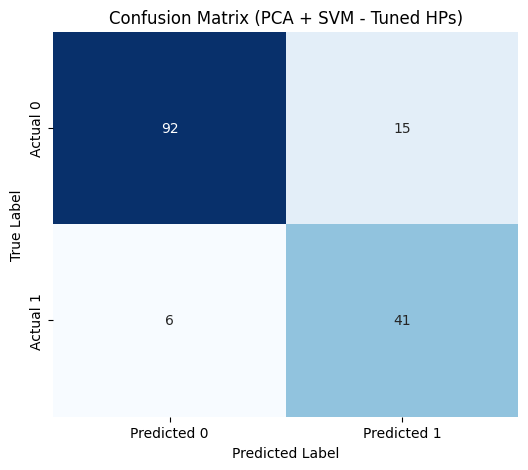

In [38]:

# --- 5. Define SVC Classifier and Hyperparameter Distribution for RandomizedSearchCV ---
svc_model_r = SVC(random_state=42)

# Define the hyperparameter distribution for SVM
param_distributions = {
    'C': np.logspace(-3, 2, 6),
    'kernel': ['linear', 'rbf', 'poly'],
    'gamma': ['scale', 'auto', 0.001, 0.01, 0.1, 1],
    'degree': [2, 3, 4],
}

# Define RandomizedSearchCV
random_search_svc = RandomizedSearchCV(
    estimator=svc_model_r,
    param_distributions=param_distributions,
    n_iter=100,
    scoring='accuracy',
    cv=10,
    verbose=2,
    random_state=42,
    n_jobs=-1
)

print("\nStarting RandomizedSearchCV for PCA + SVM...")
random_search_svc.fit(X_train_pca, y_train)

#  Evaluate the Best Model ---
print("\n--- PCA + SVM Evaluation ---")
print(f"Best Hyperparameters found: {random_search_svc.best_params_}")
print(f"Best Cross-Validation Accuracy: {random_search_svc.best_score_:.4f}")

best_svc_pca = random_search_svc.best_estimator_
y_pred_pca_svc = best_svc_pca.predict(X_test_pca)

print(f"\nTest Accuracy (PCA + SVM - Tuned HPs): {accuracy_score(y_test, y_pred_pca_svc):.4f}")
print("\nClassification Report (PCA + SVM - Tuned HPs):")
print(classification_report(y_test, y_pred_pca_svc))

cm_pca_svc = confusion_matrix(y_test, y_pred_pca_svc)
print("\nConfusion Matrix (PCA + SVM - Tuned HPs):")
print(cm_pca_svc)

plt.figure(figsize=(6, 5))
sns.heatmap(cm_pca_svc, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Predicted 0', 'Predicted 1'],
            yticklabels=['Actual 0', 'Actual 1'])
plt.title('Confusion Matrix (PCA + SVM - Tuned HPs)')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()



#Previous Model Training and Evaluation

Basic Models: Logistic Regression, KNN, SVM, Decision Trees <br>
Ensemble Learning: Random Forest, Gradient Boosting, XGBoost, LightGBM,CatBoost


###LR

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# Create and train the model
model = LogisticRegression(max_iter=1000)  # Increase max_iter to avoid convergence issues
model.fit(X_train, y_train)

# Make predictions
y_pred = model.predict(X_test)

In [ ]:
accuracy = accuracy_score(y_test, y_pred)
print(f"Model Accuracy: {accuracy:.4f}")

Model Accuracy: 0.7532


In [ ]:
from sklearn.metrics import classification_report, confusion_matrix

print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

Confusion Matrix:
 [[123  34]
 [ 23  51]]

Classification Report:
               precision    recall  f1-score   support

           0       0.84      0.78      0.81       157
           1       0.60      0.69      0.64        74

    accuracy                           0.75       231
   macro avg       0.72      0.74      0.73       231
weighted avg       0.76      0.75      0.76       231



###SVC

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [ ]:
from sklearn.svm import SVC

# Create and train the SVM model
model = SVC(kernel="rbf", C=1.0, gamma="scale")  # You can change the kernel ('linear', 'poly', 'rbf', 'sigmoid')
model.fit(X_train, y_train)

# Make predictions
y_pred = model.predict(X_test)

In [ ]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"Model Accuracy: {accuracy:.4f}")

# Confusion Matrix
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))

# Classification Report
print("\nClassification Report:\n", classification_report(y_test, y_pred))

Model Accuracy: 0.7576

Confusion Matrix:
 [[123  34]
 [ 22  52]]

Classification Report:
               precision    recall  f1-score   support

           0       0.85      0.78      0.81       157
           1       0.60      0.70      0.65        74

    accuracy                           0.76       231
   macro avg       0.73      0.74      0.73       231
weighted avg       0.77      0.76      0.76       231



###Gradient boosting

In [ ]:
from sklearn.ensemble import GradientBoostingClassifier

# Create and train the model
model = GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, max_depth=3)
model.fit(X_train, y_train)

# Make predictions
y_pred = model.predict(X_test)


In [ ]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"Model Accuracy: {accuracy:.4f}")

# Confusion Matrix
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))

# Classification Report
print("\nClassification Report:\n", classification_report(y_test, y_pred))


Model Accuracy: 0.7619

Confusion Matrix:
 [[126  31]
 [ 24  50]]

Classification Report:
               precision    recall  f1-score   support

           0       0.84      0.80      0.82       157
           1       0.62      0.68      0.65        74

    accuracy                           0.76       231
   macro avg       0.73      0.74      0.73       231
weighted avg       0.77      0.76      0.76       231



###knn

In [ ]:
from sklearn.neighbors import KNeighborsClassifier

# Create and train the KNN model
model = KNeighborsClassifier(n_neighbors=5)  # You can change the number of neighbors (k)
model.fit(X_train, y_train)

# Make predictions
y_pred = model.predict(X_test)


In [ ]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"Model Accuracy: {accuracy:.4f}")

# Confusion Matrix
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))

# Classification Report
print("\nClassification Report:\n", classification_report(y_test, y_pred))


Model Accuracy: 0.7403

Confusion Matrix:
 [[117  40]
 [ 20  54]]

Classification Report:
               precision    recall  f1-score   support

           0       0.85      0.75      0.80       157
           1       0.57      0.73      0.64        74

    accuracy                           0.74       231
   macro avg       0.71      0.74      0.72       231
weighted avg       0.76      0.74      0.75       231



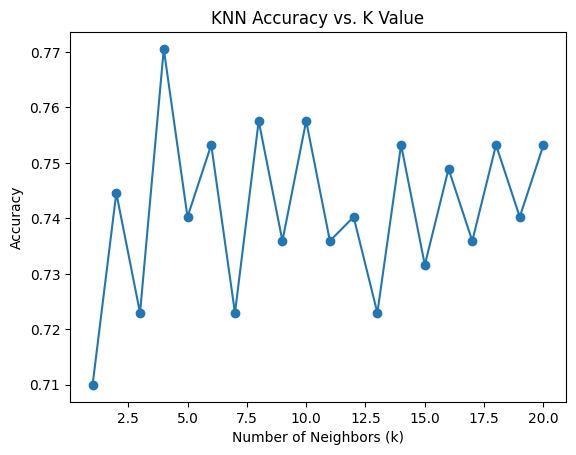

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import accuracy_score

# Try different k values
k_values = np.arange(1, 21)
accuracies = []

for k in k_values:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    accuracies.append(accuracy_score(y_test, y_pred))

# Plot accuracy vs. k
plt.plot(k_values, accuracies, marker='o')
plt.xlabel('Number of Neighbors (k)')
plt.ylabel('Accuracy')
plt.title('KNN Accuracy vs. K Value')
plt.show()


###Random Forest

In [ ]:
from sklearn.ensemble import RandomForestClassifier

# Create and train the model
model = RandomForestClassifier(n_estimators=100, random_state=42)  # You can change n_estimators
model.fit(X_train, y_train)

# Make predictions
y_pred = model.predict(X_test)


In [ ]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"Model Accuracy: {accuracy:.4f}")

# Confusion Matrix
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))

# Classification Report
print("\nClassification Report:\n", classification_report(y_test, y_pred))


Model Accuracy: 0.7792

Confusion Matrix:
 [[131  26]
 [ 25  49]]

Classification Report:
               precision    recall  f1-score   support

           0       0.84      0.83      0.84       157
           1       0.65      0.66      0.66        74

    accuracy                           0.78       231
   macro avg       0.75      0.75      0.75       231
weighted avg       0.78      0.78      0.78       231



###decision tree

In [ ]:
from sklearn.tree import DecisionTreeClassifier

# Create and train the model
model = DecisionTreeClassifier(criterion="gini", max_depth=5, random_state=42)
model.fit(X_train, y_train)

# Make predictions
y_pred = model.predict(X_test)


In [ ]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"Model Accuracy: {accuracy:.4f}")

# Confusion Matrix
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))

# Classification Report
print("\nClassification Report:\n", classification_report(y_test, y_pred))


Model Accuracy: 0.7706

Confusion Matrix:
 [[128  29]
 [ 24  50]]

Classification Report:
               precision    recall  f1-score   support

           0       0.84      0.82      0.83       157
           1       0.63      0.68      0.65        74

    accuracy                           0.77       231
   macro avg       0.74      0.75      0.74       231
weighted avg       0.78      0.77      0.77       231



### XGBoost (Extreme Gradient Boosting)

In [ ]:
import xgboost as xgb
from sklearn.model_selection import train_test_split

model = xgb.XGBClassifier()  # or XGBRegressor for regression tasks


In [ ]:
from sklearn.model_selection import GridSearchCV

# Define the hyperparameters to try
param_grid = {
    'learning_rate': [0.01, 0.1, 0.2],
    'max_depth': [3, 5, 7],
    'n_estimators': [100, 200, 300],
    'subsample': [0.7, 0.8, 1.0]
}

model = xgb.XGBClassifier()

# Grid Search
grid_search = GridSearchCV(
    estimator=model,
    param_grid=param_grid,
    scoring='accuracy',  # Or 'neg_mean_squared_error' for regression
    cv=5,                # 5-fold cross-validation
    verbose=1,           # Print progress
    n_jobs=-1            # Use all CPU cores
)

# Fit grid search
grid_search.fit(X_train, y_train)

# Best parameters
print("Best Hyperparameters:", grid_search.best_params_)
print("Best Score:", grid_search.best_score_)



Fitting 5 folds for each of 81 candidates, totalling 405 fits
Best Hyperparameters: {'learning_rate': 0.1, 'max_depth': 7, 'n_estimators': 200, 'subsample': 0.8}
Best Score: 0.8134137310906591


In [72]:
from sklearn.model_selection import RandomizedSearchCV
import xgboost as xgb
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split

# Load some sample data
X, y = load_breast_cancer(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Create the model
model = xgb.XGBClassifier()

# Define param_distributions
param_distributions = {
    'learning_rate': [0.01, 0.05, 0.1, 0.2],
    'max_depth': [3, 5, 7, 9],
    'n_estimators': [100, 200, 300, 400],
    'subsample': [0.6, 0.7, 0.8, 1.0],
    'colsample_bytree': [0.6, 0.7, 0.8, 1.0],
    'gamma': [0, 1, 5],
    'reg_alpha': [0, 0.5, 1],
    'reg_lambda': [0, 0.5, 1]
}

# RandomizedSearchCV
random_search = RandomizedSearchCV(
    estimator=model,
    param_distributions=param_distributions,  # <-- Now correctly using param_distributions
    n_iter=20,    # Try 20 random combinations
    scoring='accuracy',
    cv=5,         # 5-fold cross-validation
    verbose=1,
    n_jobs=-1,    # Use all CPU cores
    random_state=42
)

# Fit RandomizedSearchCV
random_search.fit(X_train, y_train)

# Best parameters and score
print("Best Hyperparameters:", random_search.best_params_)
print("Best Cross-validation Score:", random_search.best_score_)


Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best Hyperparameters: {'subsample': 0.8, 'reg_lambda': 0, 'reg_alpha': 0, 'n_estimators': 300, 'max_depth': 3, 'learning_rate': 0.1, 'gamma': 0, 'colsample_bytree': 1.0}
Best Cross-validation Score: 0.9736263736263737


In [ ]:
best_model = random_search.best_estimator_
y_pred = best_model.predict(X_test)

from sklearn.metrics import accuracy_score
print("Test Accuracy:", accuracy_score(y_test, y_pred))


Test Accuracy: 0.9736842105263158


In [ ]:
from xgboost import XGBClassifier

# Train the model
model = XGBClassifier(n_estimators=100, learning_rate=0.1, max_depth=3)
model.fit(X_train, y_train)

# Make predictions
y_pred = model.predict(X_test)

# Evaluate
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Classification Report:\n", classification_report(y_test, y_pred))


Accuracy: 0.7792207792207793
Classification Report:
               precision    recall  f1-score   support

           0       0.86      0.80      0.83       157
           1       0.64      0.73      0.68        74

    accuracy                           0.78       231
   macro avg       0.75      0.77      0.76       231
weighted avg       0.79      0.78      0.78       231



In [ ]:
from sklearn.metrics import classification_report, f1_score, precision_score

# Get the best model after tuning
best_model = random_search.best_estimator_

# Predict on test set
y_pred = best_model.predict(X_test)

# Show full classification report
print(classification_report(y_test, y_pred))

# OR: Print just F1 and precision
print("F1 Score:", f1_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))


              precision    recall  f1-score   support

           0       0.98      0.95      0.96        43
           1       0.97      0.99      0.98        71

    accuracy                           0.97       114
   macro avg       0.97      0.97      0.97       114
weighted avg       0.97      0.97      0.97       114

F1 Score: 0.9790209790209791
Precision: 0.9722222222222222


In [ ]:
from sklearn.metrics import precision_score, f1_score
precision = precision_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("Precision:", precision)
print("F1 Score:", f1)

ValueError: Found input variables with inconsistent numbers of samples: [114, 231]

###Naïve Bayes

In [ ]:
from sklearn.naive_bayes import GaussianNB

# Train the model
model = GaussianNB()
model.fit(X_train, y_train)

# Make predictions
y_pred = model.predict(X_test)

# Evaluate
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Classification Report:\n", classification_report(y_test, y_pred))


Accuracy: 0.7272727272727273
Classification Report:
               precision    recall  f1-score   support

           0       0.80      0.80      0.80       157
           1       0.57      0.58      0.58        74

    accuracy                           0.73       231
   macro avg       0.69      0.69      0.69       231
weighted avg       0.73      0.73      0.73       231



In [ ]:
from sklearn.neural_network import MLPClassifier

# Train the model
model = MLPClassifier(hidden_layer_sizes=(100,50), max_iter=500)
model.fit(X_train, y_train)

# Make predictions
y_pred = model.predict(X_test)

# Evaluate
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Classification Report:\n", classification_report(y_test, y_pred))

Accuracy: 0.7316017316017316
Classification Report:
               precision    recall  f1-score   support

           0       0.78      0.83      0.81       157
           1       0.59      0.51      0.55        74

    accuracy                           0.73       231
   macro avg       0.69      0.67      0.68       231
weighted avg       0.72      0.73      0.73       231



/usr/local/lib/python3.11/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


###LightGBM

In [ ]:
from lightgbm import LGBMClassifier

model = LGBMClassifier(n_estimators=100, learning_rate=0.1, max_depth=3)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))


/usr/local/lib/python3.11/dist-packages/dask/dataframe/__init__.py:42: FutureWarning: 
Dask dataframe query planning is disabled because dask-expr is not installed.

You can install it with `pip install dask[dataframe]` or `conda install dask`.
This will raise in a future version.

  warnings.warn(msg, FutureWarning)


[LightGBM] [Info] Number of positive: 343, number of negative: 343
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001071 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 816
[LightGBM] [Info] Number of data points in the train set: 686, number of used features: 8
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with 

/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


### CatBoost

In [ ]:
!pip install catboost

from catboost import CatBoostClassifier

model = CatBoostClassifier(iterations=100, learning_rate=0.1, depth=6, verbose=0)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 98.7/98.7 MB 7.1 MB/s eta 0:00:00
Accuracy: 0.7532467532467533
              precision    recall  f1-score   support

           0       0.82      0.81      0.82       157
           1       0.61      0.64      0.62        74

    accuracy                           0.75       231
   macro avg       0.72      0.72      0.72       231
weighted avg       0.76      0.75      0.75       231

